# Forward learning with FASHIONMNIST0.6 dataset

In [70]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import torchvision

In [ ]:
FILE_PATH = 'data/FashionMNIST0.6.npz'

## Prepare data

In [ ]:
dataset = np.load(FILE_PATH)
Xtr, Str = dataset["Xtr"], dataset["Str"]
Xts, Yts = dataset["Xts"], dataset["Yts"]
print(Xtr.shape)
print(Str.shape)
print(Xts.shape)
print(Yts.shape)
print("Str unique values:", np.unique(Str))
print("Yts unique values:", np.unique(Yts))

(18000, 784)
(18000,)
(3000, 784)
(3000,)
Str unique values: [0 1 2]
Yts unique values: [0 1 2]


In [ ]:
Xtr

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(18000, 784), dtype=uint8)

In [ ]:
def prepare_images(images):
    images = images.astype(np.float32)
    images = images / 255
    images = images.reshape(images.shape[0], 1, 28, 28)
    
    return images

In [ ]:
Xtr = torch.from_numpy(prepare_images(Xtr)).float()
Xts = torch.from_numpy(prepare_images(Xts)).float()

Str = torch.from_numpy(Str).long()
Yts = torch.from_numpy(Yts).long()

In [ ]:
# Random 80/20 split (change seed each run)
seed = 0
idx_tr, idx_val = train_test_split(
    np.arange(len(Xtr)), test_size=0.2, random_state=seed
)

train_loader = DataLoader(TensorDataset(Xtr[idx_tr], Str[idx_tr]), batch_size=128, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xtr[idx_val], Str[idx_val]), batch_size=128)
test_loader  = DataLoader(TensorDataset(Xts, Yts), batch_size=128)

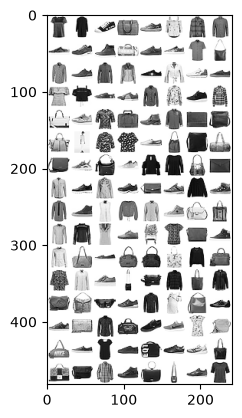

In [73]:
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

dataiter = iter(train_loader)
images, labels = next(dataiter)

# Create a grid from the images and show them
img_grid = torchvision.utils.make_grid(images)
matplotlib_imshow(img_grid, one_channel=True)

## Define model

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, input_channels, num_classes=3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(
                in_channels=input_channels,
                out_channels=16,     # Hint: 16
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,      # Must match the previous out_channels
                out_channels=32,     # Hint: 32
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Linear(
            in_features=32,        # Number of final feature channels
            out_features=num_classes,
        )

    def forward(self, x):
        x = self.net(x)
        x = self.pool(x)
        x = torch.flatten(x, start_dim=1)
        logits = self.classifier(x)

        return logits

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SmallCNN(input_channels=1, num_classes=3).to(device)

## Loss function, optimizer

In [35]:
criterion = nn.CrossEntropyLoss()           # for classification
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Apply Transition matrix

In [58]:
T = torch.tensor([
    [0.4, 0.3, 0.3],
    [0.3, 0.4, 0.3],
    [0.3, 0.3, 0.4],
], dtype=torch.float32)
print("Shape:", T.shape)

Shape: torch.Size([3, 3])


In [61]:
batch_images, batch_labels = next(iter(train_loader))

print("Input shape:", batch_images.shape)
print("Labels shape:", batch_labels.shape)

logits = model(batch_images)

print("Output shape:", logits.shape)
print("First output:", logits[0])

Input shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
Output shape: torch.Size([128, 3])
First output: tensor([-0.0698,  0.0111,  0.2116], grad_fn=<SelectBackward0>)


## Forward correction loss

In [66]:
def forward_correction_loss(logits, noisy_labels, T, epsilon=1e-8):
    p = torch.nn.functional.softmax(logits, dim=1)
    q = p @ T # noisy probabilities
    #label_column = noisy_labels.unsqueeze(1)
    log_q = torch.log(q.clamp_min(epsilon))
    loss = torch.nn.functional.nll_loss(log_q, noisy_labels)
    return loss

If both numbers match, the function is correct.

In [68]:
logits = torch.randn(8, 3)
labels = torch.randint(0, 3, (8,))
T = torch.eye(3)
print(forward_correction_loss(logits, labels, T))
print(torch.nn.functional.cross_entropy(logits, labels))

tensor(1.3879)
tensor(1.3879)


## Training loop

In [67]:
num_epochs = 20

for epoch in range(num_epochs):
    # ---------- Training ----------
    model.train()                      # turn on training mode
    running_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        # 1. Forward pass``
        outputs = model(batch_X)

        # 2. Compute loss
        loss = forward_correction_loss(outputs, batch_y, T)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Backward pass (compute gradients)
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # ---------- Validation ----------
    model.eval()                       # turn on evaluation mode
    val_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():              # no gradients needed
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            val_loss += criterion(outputs, batch_y).item()

            preds = outputs.argmax(dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train loss: {avg_train_loss:.4f} | "
          f"Val loss: {val_loss/len(val_loader):.4f} | "
          f"Val acc: {correct/total:.2%}")

Epoch 1/20 | Train loss: 1.0970 | Val loss: 1.0988 | Val acc: 36.92%
Epoch 2/20 | Train loss: 1.0968 | Val loss: 1.1041 | Val acc: 36.47%
Epoch 3/20 | Train loss: 1.0966 | Val loss: 1.1065 | Val acc: 36.50%
Epoch 4/20 | Train loss: 1.0964 | Val loss: 1.1089 | Val acc: 36.67%
Epoch 5/20 | Train loss: 1.0962 | Val loss: 1.1282 | Val acc: 36.47%
Epoch 6/20 | Train loss: 1.0959 | Val loss: 1.1219 | Val acc: 36.64%
Epoch 7/20 | Train loss: 1.0957 | Val loss: 1.1269 | Val acc: 37.89%
Epoch 8/20 | Train loss: 1.0953 | Val loss: 1.1389 | Val acc: 38.03%
Epoch 9/20 | Train loss: 1.0951 | Val loss: 1.1646 | Val acc: 38.08%
Epoch 10/20 | Train loss: 1.0948 | Val loss: 1.1899 | Val acc: 38.25%
Epoch 11/20 | Train loss: 1.0945 | Val loss: 1.2254 | Val acc: 38.31%
Epoch 12/20 | Train loss: 1.0942 | Val loss: 1.2835 | Val acc: 37.75%
Epoch 13/20 | Train loss: 1.0939 | Val loss: 1.3038 | Val acc: 38.00%
Epoch 14/20 | Train loss: 1.0937 | Val loss: 1.3378 | Val acc: 38.72%
Epoch 15/20 | Train loss: 1.0